<img src="https://github.com/Ch3ddarr/DSB-Unit-03/blob/main/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Introduction to Logistic Regression

---

### About
An introduction to Logistic Regression: what it is, how it works, and how to run a model using `scikit-learn`.

### Learning Objectives
- Fit, evaluate, and generate predictions from a Logistic Regression model in `scikit-learn`.

### Learning Objectives
- Describe the principles of Logistic Regression.
- Describe how logistic regression is similar to and different from linear regression.
- Interpret the coefficients of a Logistic Regression model.
- State the assumptions of a Logistic Regression model.
- Fit, evaluate, and generate predictions from a Logistic Regression model in `scikit-learn`.

### Notebook Guide
- Imports
- Data Set: Graduate School Admissions
- Predicting Admission to College
- Fitting and making predictions with a logistic regression model in `scikit-learn`
- Now You Try: Multivariate Logistic Regression
- Interpreting the coefficients in a logistic regression model
- What about Multiclass Classification?
- Conclusion and Bonuses

# Imports

In [54]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Import train_test_split
from sklearn.model_selection import train_test_split

# Import DummyClassifier to calculate the baseline (null) model
from sklearn.dummy import DummyClassifier

# Import logistic regression
from sklearn.linear_model import LogisticRegression

# Data Set: Graduate School Admissions

---

In this session, we'll be applying logistic regression to solve the following problem: **"Given their GPA, will a student be admitted to a specific graduate program?"**

In [55]:
# Read in the data
admissions_org = pd.read_csv('https://raw.githubusercontent.com/Ch3ddarr/DSB-Unit-03/refs/heads/main/data/grad_admissions.csv', sep = ',' )

In [56]:
# Check first five rows
admissions_org.head()

,admit,gre,gpa
0,0,380.0,2.915018
1,1,660.0,4.044540
2,1,800.0,4.950714
3,1,640.0,3.921994
4,0,520.0,2.069878


In [57]:
# Look at the overall properties of the data
admissions_org.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   admit   4000 non-null   int64  
 1   gre     3980 non-null   float64
 2   gpa     3980 non-null   float64
dtypes: float64(2), int64(1)
memory usage: 93.9 KB


The columns are:
- `admit`: A binary 0/1 variable indicating whether or not a student was admitted, where 1 means admitted and 0 means not admitted.
- `gre`: The student's [GRE (Graduate Record Exam)](https://en.wikipedia.org/wiki/Graduate_Record_Examinations) score.
- `gpa`: The student's [GPA](https://en.wikipedia.org/wiki/Grading_in_education).

In [58]:
# How many missing values do we have in each column?
admissions_org.isnull().sum()

,0
admit,0
gre,20
gpa,20


In [59]:
# Drop every row that has an NA
admissions = admissions_org.dropna()
admissions.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3970 entries, 0 to 3999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   admit   3970 non-null   int64  
 1   gre     3970 non-null   float64
 2   gpa     3970 non-null   float64
dtypes: float64(2), int64(1)
memory usage: 124.1 KB


<details><summary>What assumption are we making when we drop rows that have at least one NA in it?</summary>
    
- We assume that what we drop looks like what we have observed. That is, there's nothing special about the rows we happened to drop.
- We might say that what we dropped is a random sample of our whole data.
- It's not important to know this now, but the formal term is that our data is **missing completely at random**.
</details>

# Predicting Admission to College
---

<a id='plot-reg'></a>
### What if we predicted `admit` with `gpa` using Linear Regression?

Looking at the plot below, what are problems with using a regression?

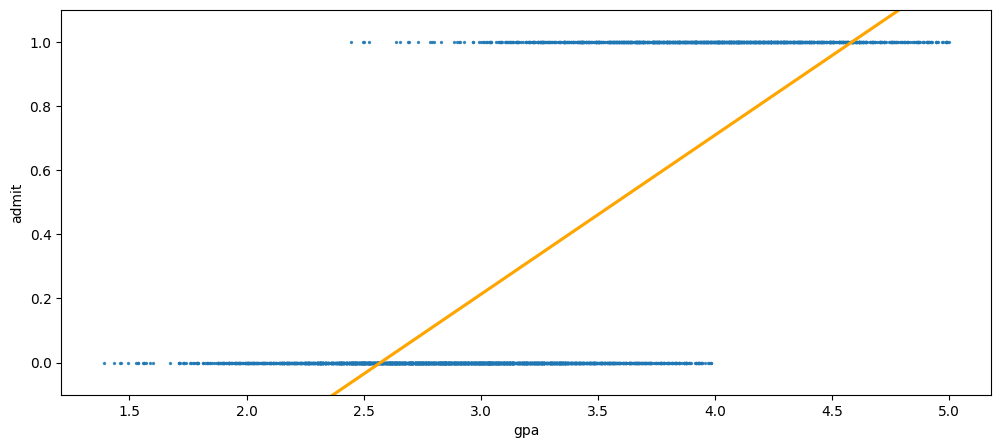

In [60]:
plt.figure(figsize = (12, 5))
sns.regplot(x=admissions['gpa'], y=admissions['admit'], data=admissions,
            ci = False, scatter_kws = {'s': 2},
            line_kws = {'color': 'orange'})
plt.ylim(-0.1, 1.1);

<details><summary>The big problem...</summary>
    
...is that Linear Regression we predict a continuous variable, but here we want to predict a class: one of two options.

</details>

## Predicting a Binary Class

In our case we have two classes: `1=admitted` and `0=rejected`.

The logistic regression is still solving for $\hat{y}$. However, in our binary classification case, $\hat{y}$ will be the probability of $y$ being one of the classes.

$$
\hat{y} = P(y = 1)
$$

We'll still try to fit a "line" of best fit to this... except it won't be perfectly linear. We need to *guarantee* that the right-hand side of the regression equation will evaluate to a probability. (That is, some number between 0 and 1!)

# Fitting and making predictions with a logistic regression model in `scikit-learn`
---

We can follow the same steps to build a logistic regression model that we follow to build a linear regression model.

1. Define X & y
2. Instantiate the model
3. Fit the model
4. Generate predictions
5. Evaluate model

In [70]:
# Step 1: Define X & y, and split into training & testing sets
X = admissions.drop(columns=['admit'])
y = admissions['admit']
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=50)

        gre       gpa
0     380.0  2.915018
1     660.0  4.044540
2     800.0  4.950714
3     640.0  3.921994
4     520.0  2.069878
...     ...       ...
3995  620.0  3.557893
3996  560.0  2.705599
3997  460.0  2.235428
3998  700.0  3.120059
3999  600.0  3.728633

[3970 rows x 2 columns]


In [62]:
# Step 2: Instantiate our model
logreg = LogisticRegression()

# Step 3: Fit our model
logreg.fit(X_train,y_train)

LogisticRegression()

In [63]:
print(f'Logistic Regression Intercept:{logreg.intercept_}')
# the intercept_ is the calue of the log-odds when all the features are equal to zero.
# in this case, it represents the lg-odds of being admitted to graduate school when
# the GPA is zero. The intercept can be used to calculate the probability of being
# admitted to graduate school for a student with a GPA of zero.
# -17.45 in this case means that when the GPA is zero, the log-odds of being admitted to
# graduate school is -17.45, which correspons to a very low probability of being admitted.

Logistic Regression Intercept:[-16.6414603]


In [64]:
print(f'Logistic Regression COefficient: {logreg.coef_}')
# 4.9 in this case means that for every one-unit increase
# in GPA, the log-odds of being admitted to graduate school increase by 4.9

Logistic Regression COefficient: [[-2.13947722e-03  5.04549367e+00]]


There are two methods in `sklearn` to be aware of when using logistic regression:
- `.predict()`
- `.predict_proba()`

In [69]:
# Step 4 (part 1): Generate predicted values
y_hat = logreg.predict(X_test)
y_hat

array([0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,

In [66]:
# Step 4 (part 2): Generate predicted probabilities
y_hat_proba = np.round(logreg.predict_proba(X_test),3)
y_hat_proba

array([[0.905, 0.095],
       [0.834, 0.166],
       [0.994, 0.006],
       ...,
       [0.544, 0.456],
       [0.991, 0.009],
       [0.986, 0.014]])

<details><summary>How would you interpret the predict_proba() output?</summary>
    
- This shows the probability of being rejected ($P(y=0)$) and the probability of being admitted ($P(y=1)$) for each observation in the testing data set.
- The first array, corresponds to the first testing observation.
    - The `.predict()` value for this observation is 0. This is because $P(y=0) > P(y=1)$.
- The second array, corresponds to the second testing observation.
    - The `.predict()` value for this observation is 0. This is because $P(y=0) > P(y=1)$.
</details>

ValueError: x and y must be the same size

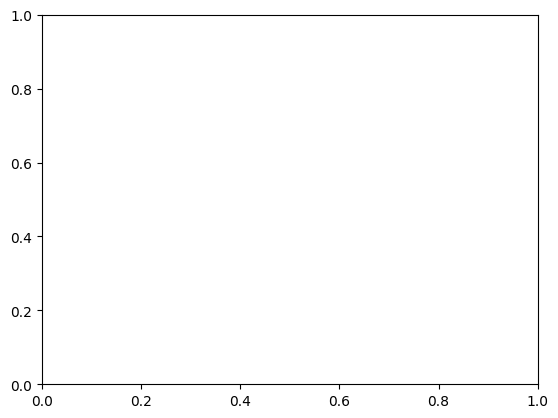

In [74]:
# Visualizing logistic regression probabilities
plt.figure()
plt.scatter(X_test, y_test, s=10);

plt.plot(X_test.sort_values('gpa'),
         logreg.predict_proba(X_test.sort_values('gpa'))[:,1],
         color='red', alpha = 0.8, lw=3)

plt.xlabel('GPA')
plt.ylabel('Admit')
plt.title('Predicting admission from GPA');

In [71]:
# Step 5: Evaluate model
logreg.score(X_train, y_train)

0.8951965065502183

In [72]:
logreg.score(X_test, y_test)

0.904330312185297

By default, the `.score()` method for classification models gives us the accuracy score.

$$
\begin{eqnarray*}
\text{Accuracy} = \frac{\text{number of correct predictions}}{\text{number of total predictions}}
\end{eqnarray*}
$$

<details><summary>Remind me: what does .score() tell me for a regression model?</summary>
    
- The $R^2$ score.
- Remember that $R^2$ is the proportion of variance in our $Y$ values that are explained by our model.
</details>

In [75]:
# Compare with a baseline (null) model
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)
dummy_clf.predict(X_test)
dummy_clf.score(X_test, y_test)

0.7089627391742196

# Now You Try: Multivariate Logistic Regression

---

Create a logistic regression model that uses GRE and both GPA and GRE.  How does it compare with the simple model we created?

In [76]:
X = admissions[['gpa', 'gre']]
y = admissions['admit']

X_train, X_test, y_train, y_test = train_test_split(X,y, random_state = 50)

In [78]:
logreg2 = LogisticRegression()

logreg2.fit(X_train, y_train)

LogisticRegression()

In [79]:
logreg2.predict(X_test)[:10]

array([0, 0, 0, 1, 0, 0, 0, 1, 1, 0])

In [81]:
np.round(logreg2.predict_proba(X_test)[:10],3)

array([[0.905, 0.095],
       [0.834, 0.166],
       [0.994, 0.006],
       [0.27 , 0.73 ],
       [0.594, 0.406],
       [0.644, 0.356],
       [0.959, 0.041],
       [0.064, 0.936],
       [0.019, 0.981],
       [0.977, 0.023]])

In [83]:
logreg2.score(X_train, y_train)

0.8951965065502183

In [84]:
logreg2.score(X_test, y_test)

0.904330312185297

---

To the slides!

---

# Interpreting the coefficients in a logistic regression model
---

## Using the log-odds: the natural logarithm of the odds

The combination of converting the "probability of success" to "odds of success," then taking the logarithm of that is called the **logit link function**.

$$
\text{logit}\big(P(y=1)\big) = \ln\bigg(\frac{P(y=1)}{1-P(y=1)}\bigg) = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p
$$

We've bent our line how we want... but how do we interpret our coefficients?

Given this model, **a one-unit change in $x_i$ implies a $\beta_i$ unit change in the log odds of success**.

**This is annoying**.  We often convert log-odds back to "regular odds" when interpreting our coefficient (and then on to probability)... our mind understands odds better than the log of odds.

We can get rid of the natural log on the left-hand side by "exponentiating" each side.
$$
\begin{eqnarray*}
\Rightarrow \frac{P(y=1)}{1-P(y=1)} &=& e^{\Bigg(\beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p\Bigg)} \\
\end{eqnarray*}
$$

### Interpretation:
**A one-unit change in $x_i$ means that success is $e^{\beta_i}$ times as likely.**

<details><summary> I want to interpret the coefficient $\hat{\beta}_1$ for my logistic regression model. How would I interpret this coefficient?</summary>
    
- Our model is that $\log\bigg(\frac{P(admit=1)}{1-P(admit=1)}\bigg) = \beta_0 + \beta_1\text{GPA}$.
- As GPA increases by 1, the log-odds of someone being admitted increases by 4.91.
- As GPA increases by 1, someone is $e^{4.92}$ times more likely to be admitted.
- As GPA increases by 1, someone is about 135 times more likely to be admitted to grad school.
</details>

> Hint: Use the [np.exp](https://docs.scipy.org/doc/numpy/reference/generated/numpy.exp.html) function.

In [ ]:
# Use np.exp() to exponentiate the coefficient.


## Many people prefer to think in probability instead of odds

Let's convert our result to a probability to make it easier to understand.

In [ ]:
# First of all, let's look at the intercept



### Odds to Probabilities

Remember:

$$\ln \left({p\over 1-p}\right) = \beta_0 + \beta_1x$$

That means we'll get out the log odds if we compute the intercept plus the coefficient times a value for `GPA`.

**Compute the log odds of `admit` when `GPA=3`.**

In [ ]:
# Compute predicted log odds for GPA=3 using the equation


In [ ]:
# Convert log odds to odds


In [ ]:
# Convert odds to probability


You can confirm this is the same as the value you would get out of the `.predict_proba()` method of the `scikit-learn` object.

In [ ]:
# Compute predicted probability for GPA=3 using the predict_proba method.


In [ ]:
# Increasing GPA by 0.5 (so that GPA=3.5)


**Interpretation:** A GPA score of 3.5 gives you a 43% chance of being admitted to college.

## (BONUS) Or, another way to calculate this manually...

The logit function...

$$\ln \left({p\over 1-p}\right) = \beta_0 + \beta_1x$$


...can be rearranged into the logistic function:

$$\hat{p} = \frac{e^{\beta_0 + \beta_1x}} {1 + e^{\beta_0 + \beta_1x}}$$

where
$$ \beta_0 = \text {coefficient of our intercept} $$
$$ \beta_1 = \text {coefficient of our first feature} $$

---

To the slides!

---

# What about Multiclass Classification?
---

Logistic regression is **only** for binary classification problems! However, there are two "hacks" that allow us to fit multiclass classification problems using the same/similar methodology. They are:

## Multinomial logistic regression
Normally, logistic regression is based off of the _Bernoulli distribution_, since our y-variable can be represented with a Bernoulli trial. We can instead base our y-variable off the _multinomial distribution_ and fit a model that way. It's more theoretically "pure" than OVR below, but less commonly used.

**How?**
```python
LogisticRegression(solver='...')
```
All solvers except `liblinear` will handle multiclass (the default is `lbfgs`).


## One-vs-Rest (OVR) logistic regression
A more common alternative is the _one-versus-rest_ technique. It works like this:

1. For category $k$, set $y = 1$ when the response is $k$ and $y = 0$ otherwise
1. Fit a logistic regression with this new $y$, and record the $\hat y$ for each observation
1. Repeat steps 1 and 2 for each category in our response variable
1. The true prediction is the $\hat y$ with the highest probability after all models are fit


**How?**

```python
sklearn.multiclass.OneVsRestClassifier()
```
You cannot do OVR in `LogisticRegression` in `scikit-learn`, but the library offers a `OneVsRestClassifier` classifier specifically for it: [`scikit-learn` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html#sklearn.multiclass.OneVsRestClassifier)

#### (BONUS - outside of class) Try multinomial regression with the iris data set.

# Conclusion and Bonuses
---

The goal of logistic regression is to find the best-fitting model to describe the relationship between a binary outcome and a set of independent variables.

Logistic regression generates the coefficients of a formula to predict a logit transformation of the probability that the characteristic of interest is present.

## Interview Questions

<details><summary>What is the difference between a classification and a regression problem?</summary>
    
- A classification problem has a categorical $Y$ variable. A regression problem has a numeric $Y$ variable.
</details>

<details><summary>What are some of the benefits of logistic regression as a classifier?</summary>

(Answers may vary; this is not an exhaustive list!)
- Logistic regression is a classification algorithm that shares similar properties to linear regression.
- The coefficients in a logistic regression model are interpretable. (They represent the change in log-odds caused by the input variables.)
- Logistic regression is a very fast model to fit and generate predictions from.
- It is by far the most common classification algorithm.

**Note**: The original interview question was "If you're comparing decision trees and logistic regression, what are the pros and cons of each?"
</details>

## (BONUS) Solving for the Beta Coefficients

Logistic regression minimizes the "deviance," which is similar to the residual sum of squares in linear regression, but is a more general form.

**There's no closed-form solution to the beta coefficients like in linear regression, and the betas are found through optimization procedures.**
- We can't just do $\hat{\beta} = (X^TX)^{-1}X^Ty$ like we can in linear regression!

The `solver` hyperparameter in sklearn's `LogisticRegression` class specifies which method should be used to solve for the optimal beta coefficients (the coefficients that minimize our cost function). [This](https://www.linkedin.com/posts/justmarkham_sklearntips-machinelearning-python-activity-6654000730321534976-Um6C/) is a good post by Kevin Markham that compares the solvers.

If you're particularly interested in the math, here are two helpful resources:
- [A good blog post](http://www.win-vector.com/blog/2011/09/the-simpler-derivation-of-logistic-regression/) on the logistic regression beta coefficient derivation.
- [This paper](https://www.stat.cmu.edu/~cshalizi/402/lectures/14-logistic-regression/lecture-14.pdf) is also a good reference.

## (BONUS) The Logistic Function

The inverse function of the logit is called the **logistic function**.

By inverting the logit, we can have the right side of our regression equation solve explicitly for $P(y = 1)$:

$$
P(y=1) = logit^{-1}\left(\beta_0 + \sum_{j}^p\beta_jx_j\right)
$$

Where:

$$
logit^{-1}(a) = logistic(a) = \frac{e^{a}}{e^{a} + 1}
$$

Giving us:

$$
P(y=1) = \frac{e^{\left(\beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p\right)}}{e^{\left(\beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p\right)}+1}
$$